In [105]:
## Imports
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold


from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score
)

In [107]:
df = pd.read_csv(r"C:\Users\hp\Downloads\manufacturing_cleaned.csv")
df.head()

,record_id,machine_id,production_line,batch_id,shift,product_type,ambient_temperature,humidity,air_pressure,ambient_vibration,...,downtime_minutes,maintenance_frequency,production_cost_per_unit,resource_efficiency,production_efficiency,energy_saving_pct,downtime_reduction_pct,cost_reduction_pct,benefit_score,operation_mode
0,1,M07,Line_A,B0343,Morning,Product_C,24.657935,69.272037,102.335679,0.366190,...,25.081059,2.172029,8.028928,99.0,99.0,9.364688,49.353148,26.199425,68.260235,High_Throughput
1,2,M20,Line_E,B0593,Afternoon,Product_D,15.953337,59.927354,100.055317,0.472410,...,20.400191,2.576074,8.537013,99.0,99.0,3.129223,56.434784,30.016525,68.491891,High_Throughput
2,3,M15,Line_E,B0205,Afternoon,Product_C,21.761215,44.487079,102.794636,0.478138,...,11.608597,2.357031,7.372440,99.0,99.0,6.433856,61.539859,33.412663,68.837230,Balanced_Production
3,4,M11,Line_B,B0993,Morning,Product_A,21.973528,59.022870,98.258859,0.417760,...,25.542778,2.840125,8.622625,99.0,99.0,3.284783,43.948708,34.699694,67.074754,Balanced_Production
4,5,M08,Line_E,B0961,Night,Product_C,20.595578,54.665654,99.217605,0.283555,...,19.759181,3.410520,7.521289,99.0,99.0,12.958237,52.025084,31.553079,69.084109,Precision_Quality


### Manufacturing Machine Performance Prediction Using Logistic Regression

In [110]:
## create fault target 
df['machine_fault'] = (
    df['fault_event_count'] > 0
).astype(int)

In [112]:
## check target distribution
print("Fault Distribution:")
print(df['machine_fault'].value_counts())

print("\nFault Percentage:")
print(df['machine_fault'].value_counts(normalize=True) * 100)

## عشان نعرف عدد record اللي فيها أعطال وعدد records اللي مفيهاش أعطال.

Fault Distribution:
machine_fault
1    13168
0     1832
Name: count, dtype: int64

Fault Percentage:
machine_fault
1    87.786667
0    12.213333
Name: proportion, dtype: float64


In [114]:
## Check Operation Mode
print(df['operation_mode'].value_counts())

print("\nPercentage:")
print(df['operation_mode'].value_counts(normalize=True) * 100)

operation_mode
Balanced_Production    5250
Energy_Efficient       3750
High_Throughput        3000
Precision_Quality      3000
Name: count, dtype: int64

Percentage:
operation_mode
Balanced_Production    35.0
Energy_Efficient       25.0
High_Throughput        20.0
Precision_Quality      20.0
Name: proportion, dtype: float64


In [116]:
print(df['defect_rate'].describe())

count    15000.000000
mean         3.905590
std          0.744146
min          0.930878
25%          3.413795
50%          3.905891
75%          4.412720
max          6.798653
Name: defect_rate, dtype: float64


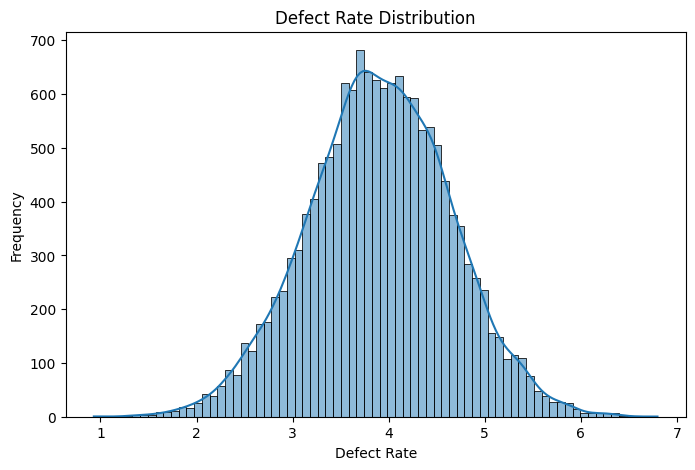

In [118]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df['defect_rate'],
    kde=True
)

plt.title('Defect Rate Distribution')
plt.xlabel('Defect Rate')
plt.ylabel('Frequency')

plt.show()

In [119]:
numeric_features = [
    'ambient_temperature',
    'humidity',
    'air_pressure',
    'ambient_vibration',
    'motor_temperature',
    'spindle_speed',
    'motor_current',
    'torque',
    'vibration',
    'acoustic_level',
    'bearing_temperature',
    'process_temperature',
    'hydraulic_pressure',
    'flow_rate',
    'coolant_temperature',
    'material_feed_rate',
    'feed_pressure',
    'cycle_time',
    'throughput_rate'
]

categorical_features = [
    'machine_id',
    'production_line',
    'shift',
    'product_type',
    'operation_mode'
]

In [120]:
features = numeric_features + categorical_features

X = df[features]

y = df['machine_fault']

In [121]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [122]:
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

### SimpleImputer: يعالج أي Missing Values متبقية.
### StandardScaler: يوحّد مقياس الـ Numeric Features.
### OneHotEncoder: يحوّل الـ Categorical Features لأرقام.
### ColumnTransformer: يطبق كل معالجة على الأعمدة المناسبة.


In [128]:
from sklearn.linear_model import LogisticRegression

fault_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=2000,
        class_weight='balanced'
    ))
])

fault_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int32](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['ambient_temperature','humidity','air_pressure',...,'shift', 'product_type','operation_mode']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``rem

In [129]:
from sklearn.metrics import precision_score, recall_score, f1_score

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

for threshold in thresholds:

    y_pred_threshold = (y_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")

    print("Fault Precision:",
          precision_score(y_test, y_pred_threshold, pos_label=1))

    print("Fault Recall:",
          recall_score(y_test, y_pred_threshold, pos_label=1))

    print("Fault F1:",
          f1_score(y_test, y_pred_threshold, pos_label=1))


Threshold: 0.3
Fault Precision: 0.9105222734254992
Fault Recall: 0.9001518602885346
Fault F1: 0.905307369224895

Threshold: 0.4
Fault Precision: 0.9255874673629243
Fault Recall: 0.8075170842824602
Fault F1: 0.8625304136253041

Threshold: 0.5
Fault Precision: 0.9424643584521385
Fault Recall: 0.7027334851936219
Fault F1: 0.8051326663766856

Threshold: 0.6
Fault Precision: 0.9590909090909091
Fault Recall: 0.5607441154138193
Fault F1: 0.7077144226161955

Threshold: 0.7
Fault Precision: 0.976063829787234
Fault Recall: 0.417995444191344
Fault F1: 0.5853269537480064


              precision    recall  f1-score   support

           0       0.34      0.36      0.35       366
           1       0.91      0.90      0.91      2634

    accuracy                           0.83      3000
   macro avg       0.62      0.63      0.63      3000
weighted avg       0.84      0.83      0.84      3000



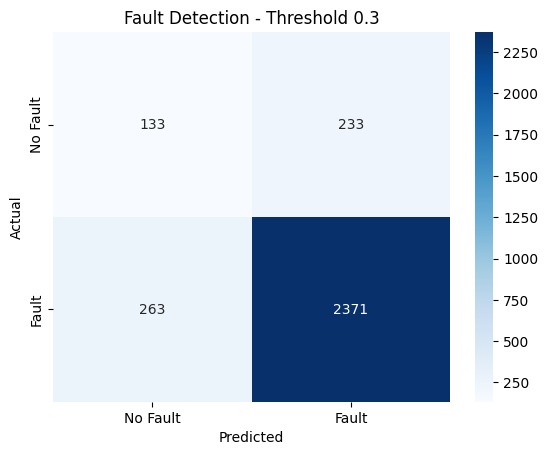

In [130]:
best_threshold = 0.3

y_pred_best = (y_prob >= best_threshold).astype(int)

print(classification_report(y_test, y_pred_best))

cm = confusion_matrix(y_test, y_pred_best)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Fault', 'Fault'],
    yticklabels=['No Fault', 'Fault']
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Fault Detection - Threshold 0.3')
plt.show()

### Model2 Quality Prediction

In [132]:
# Calculate the median threshold
quality_threshold = df['defect_rate'].median()

# Create binary target
df['high_defect'] = (
    df['defect_rate'] > quality_threshold
).astype(int)

print("Quality Threshold:", quality_threshold)

print("\nDefect Distribution:")
print(df['high_defect'].value_counts())

print("\nDefect Percentage:")
print(df['high_defect'].value_counts(normalize=True) * 100)

Quality Threshold: 3.9058908784786057

Defect Distribution:
high_defect
0    7500
1    7500
Name: count, dtype: int64

Defect Percentage:
high_defect
0    50.0
1    50.0
Name: proportion, dtype: float64


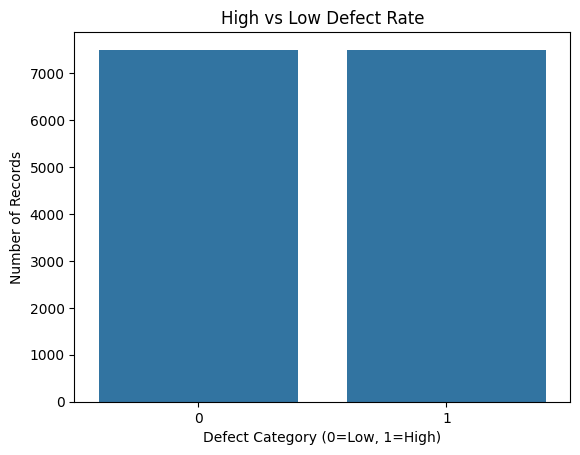

In [133]:
sns.countplot(
    data=df,
    x='high_defect'
)

plt.title('High vs Low Defect Rate')
plt.xlabel('Defect Category (0=Low, 1=High)')
plt.ylabel('Number of Records')
plt.show()

In [136]:
quality_numeric_features = [
    'ambient_temperature',
    'humidity',
    'air_pressure',
    'ambient_vibration',
    'motor_temperature',
    'spindle_speed',
    'motor_current',
    'torque',
    'vibration',
    'acoustic_level',
    'bearing_temperature',
    'process_temperature',
    'hydraulic_pressure',
    'flow_rate',
    'coolant_temperature',
    'material_feed_rate',
    'feed_pressure',
    'cycle_time',
    'throughput_rate'
]

quality_categorical_features = [
    'machine_id',
    'production_line',
    'shift',
    'product_type',
    'operation_mode'
]

In [137]:
quality_features = (
    quality_numeric_features +
    quality_categorical_features
)

X_quality = df[quality_features]

y_quality = df['high_defect']

In [139]:
Xq_train, Xq_test, yq_train, yq_test = train_test_split(
    X_quality,
    y_quality,
    test_size=0.2,
    random_state=42,
    stratify=y_quality
)

print("Training Shape:", Xq_train.shape)
print("Testing Shape:", Xq_test.shape)

Training Shape: (12000, 24)
Testing Shape: (3000, 24)


In [141]:
quality_numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

quality_categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

quality_preprocessor = ColumnTransformer([
    ('num', quality_numeric_transformer, quality_numeric_features),
    ('cat', quality_categorical_transformer, quality_categorical_features)
])

In [165]:
quality_model = Pipeline([
    ('preprocessor', quality_preprocessor),
    ('classifier', LogisticRegression(max_iter=2000))
])

quality_model.fit(Xq_train, yq_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int32](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['ambient_temperature','humidity','air_pressure',...,'shift', 'product_type','operation_mode']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``rem

In [167]:
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__class_weight': [None, 'balanced'],
    'classifier__solver': ['lbfgs']
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=quality_model_no_machine,
    param_grid=param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(Xnm_train, ynm_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV F1 Score:", grid_search.best_score_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters: {'classifier__C': 10, 'classifier__class_weight': None, 'classifier__solver': 'lbfgs'}
Best CV F1 Score: 0.6214156850147206


Final Test Accuracy: 0.647

Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.64      0.64      1500
           1       0.65      0.65      0.65      1500

    accuracy                           0.65      3000
   macro avg       0.65      0.65      0.65      3000
weighted avg       0.65      0.65      0.65      3000



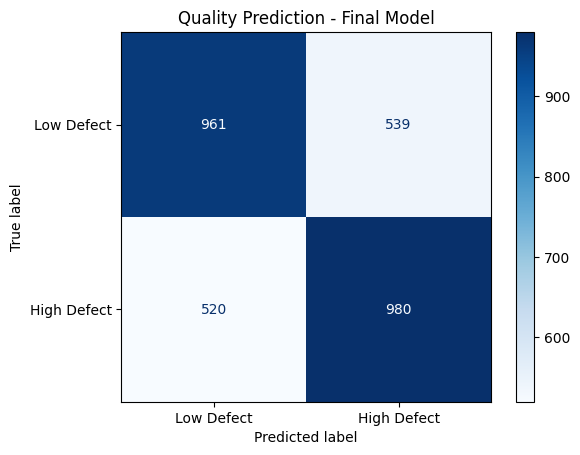

In [169]:
# Get the best model
best_quality_model = grid_search.best_estimator_

# Predict on unseen test data
y_final_pred = best_quality_model.predict(Xnm_test)

# Evaluate
print("Final Test Accuracy:",
      accuracy_score(ynm_test, y_final_pred))

print("\nClassification Report:")
print(classification_report(ynm_test, y_final_pred))

# Confusion Matrix
cm = confusion_matrix(ynm_test, y_final_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Low Defect', 'High Defect']
)

disp.plot(cmap='Blues')
plt.title("Quality Prediction - Final Model")
plt.show()

In [171]:
feature_names = (
    best_quality_model
    .named_steps['preprocessor']
    .get_feature_names_out()
)

coefficients = (
    best_quality_model
    .named_steps['classifier']
    .coef_[0]
)

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients,
    'Importance': np.abs(coefficients)
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance.head(15))

                                    Feature  Coefficient  Importance
32     cat__operation_mode_Energy_Efficient     0.701199    0.701199
33      cat__operation_mode_High_Throughput    -0.645949    0.645949
18                     num__throughput_rate     0.330218    0.330218
11                 num__process_temperature     0.306700    0.306700
8                            num__vibration     0.256836    0.256836
34    cat__operation_mode_Precision_Quality    -0.168382    0.168382
31  cat__operation_mode_Balanced_Production     0.091855    0.091855
5                        num__spindle_speed    -0.082941    0.082941
4                    num__motor_temperature     0.051089    0.051089
20              cat__production_line_Line_B    -0.044568    0.044568
10                 num__bearing_temperature    -0.043977    0.043977
0                  num__ambient_temperature     0.043565    0.043565
19              cat__production_line_Line_A    -0.038062    0.038062
25                       cat__shif

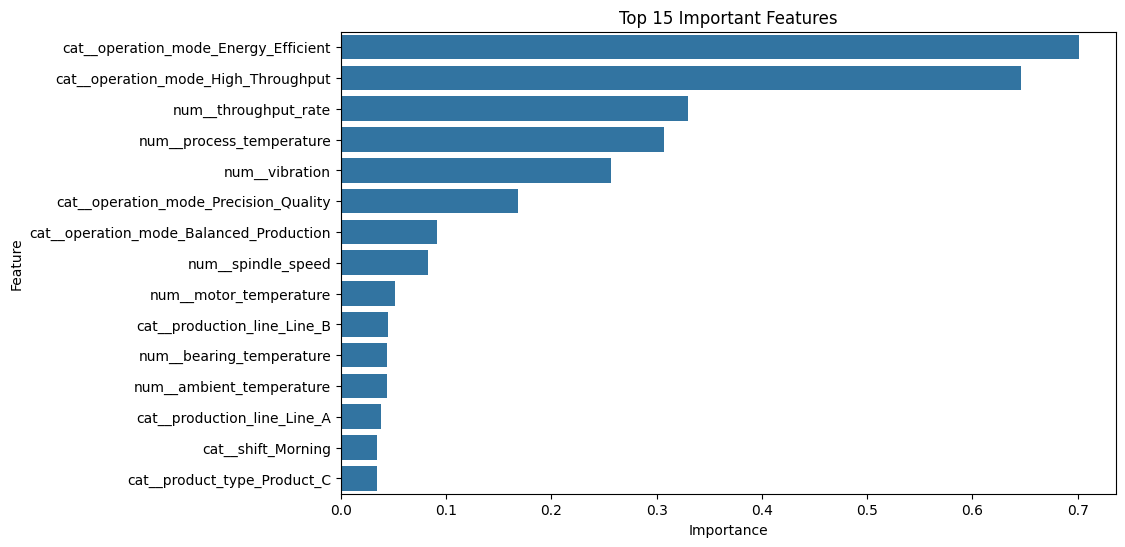

In [173]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_features,
    x='Importance',
    y='Feature'
)

plt.title("Top 15 Important Features")
plt.show()

### Model3 Operational Efficiency Prediction

In [176]:
# Check target distribution
print("Operation Mode Distribution:")
print(df['operation_mode'].value_counts())

print("\nOperation Mode Percentage:")
print(df['operation_mode'].value_counts(normalize=True) * 100)

Operation Mode Distribution:
operation_mode
Balanced_Production    5250
Energy_Efficient       3750
High_Throughput        3000
Precision_Quality      3000
Name: count, dtype: int64

Operation Mode Percentage:
operation_mode
Balanced_Production    35.0
Energy_Efficient       25.0
High_Throughput        20.0
Precision_Quality      20.0
Name: proportion, dtype: float64


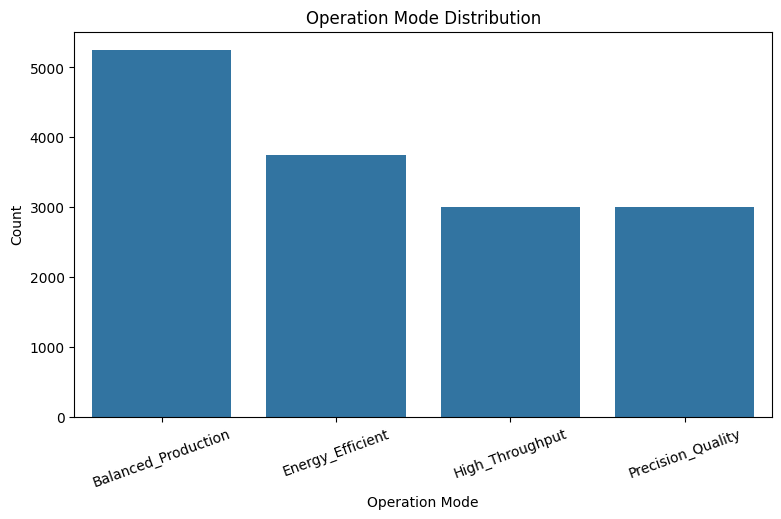

In [178]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='operation_mode',
    order=df['operation_mode'].value_counts().index
)

plt.title("Operation Mode Distribution")
plt.xlabel("Operation Mode")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.show()

In [180]:
numeric_features = [
    'ambient_temperature',
    'humidity',
    'air_pressure',
    'ambient_vibration',
    'motor_temperature',
    'spindle_speed',
    'motor_current',
    'torque',
    'vibration',
    'acoustic_level',
    'bearing_temperature',
    'process_temperature',
    'hydraulic_pressure',
    'flow_rate',
    'coolant_temperature',
    'material_feed_rate',
    'feed_pressure',
    'cycle_time',
    'throughput_rate'
]

categorical_features = [
    'production_line',
    'shift',
    'product_type'
]

features = numeric_features + categorical_features

X = df[features]
y = df['operation_mode']

In [182]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

Training Shape: (12000, 22)
Testing Shape: (3000, 22)

Training Target Distribution:
operation_mode
Balanced_Production    4200
Energy_Efficient       3000
Precision_Quality      2400
High_Throughput        2400
Name: count, dtype: int64


In [184]:
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

In [186]:
efficiency_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=3000,
        class_weight='balanced'
    ))
])

efficiency_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](4,)","['Balanced_Production','Energy_Efficient','High_Throughput', 'Precision_Quality']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](22,)","['ambient_temperature','humidity','air_pressure',...,'production_line', 'shift','product_type']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,22
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the

In [188]:
y_pred = efficiency_model.predict(X_test)

print("Initial Accuracy:",
      accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Initial Accuracy: 0.42333333333333334

Classification Report:
                     precision    recall  f1-score   support

Balanced_Production       0.41      0.24      0.30      1050
   Energy_Efficient       0.51      0.67      0.58       750
    High_Throughput       0.45      0.64      0.53       600
  Precision_Quality       0.24      0.22      0.23       600

           accuracy                           0.42      3000
          macro avg       0.40      0.44      0.41      3000
       weighted avg       0.41      0.42      0.40      3000



In [190]:
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__class_weight': [None, 'balanced'],
    'classifier__solver': ['lbfgs']
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=efficiency_model,
    param_grid=param_grid,
    scoring='f1_macro',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV F1 Macro Score:", grid_search.best_score_)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best Parameters: {'classifier__C': 10, 'classifier__class_weight': 'balanced', 'classifier__solver': 'lbfgs'}
Best CV F1 Macro Score: 0.3995845296999491


In [191]:
best_efficiency_model = grid_search.best_estimator_

y_final_pred = best_efficiency_model.predict(X_test)

print("Final Test Accuracy:",
      accuracy_score(y_test, y_final_pred))

print("\nFinal Classification Report:")
print(classification_report(y_test, y_final_pred))

Final Test Accuracy: 0.4226666666666667

Final Classification Report:
                     precision    recall  f1-score   support

Balanced_Production       0.41      0.24      0.30      1050
   Energy_Efficient       0.51      0.67      0.58       750
    High_Throughput       0.45      0.63      0.52       600
  Precision_Quality       0.24      0.22      0.23       600

           accuracy                           0.42      3000
          macro avg       0.40      0.44      0.41      3000
       weighted avg       0.41      0.42      0.40      3000



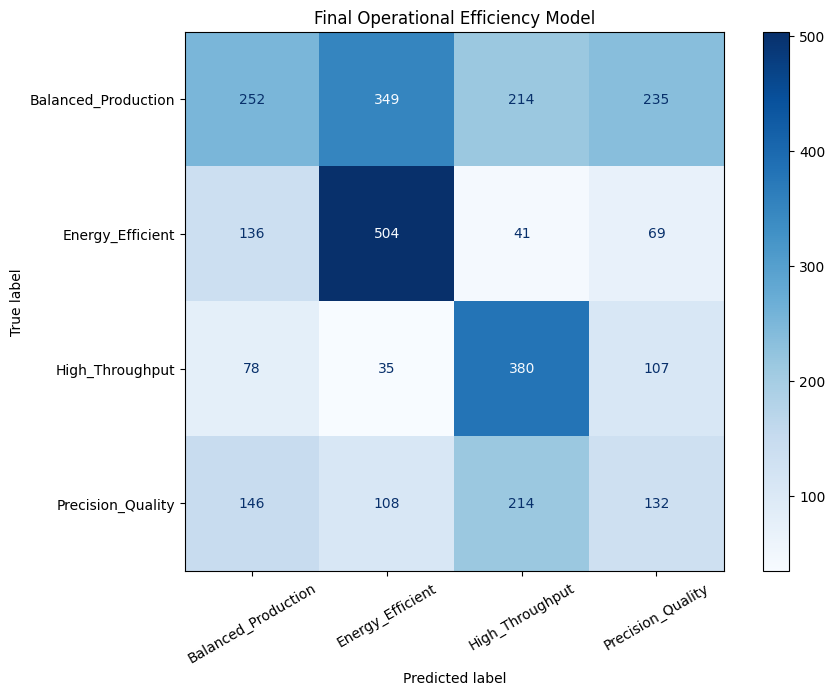

In [192]:
cm = confusion_matrix(
    y_test,
    y_final_pred,
    labels=best_efficiency_model.classes_
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=best_efficiency_model.classes_
)

fig, ax = plt.subplots(figsize=(10, 7))

disp.plot(
    cmap='Blues',
    xticks_rotation=30,
    ax=ax
)

plt.title("Final Operational Efficiency Model")
plt.show()